# Online Shopper Purchase Prediction

**Machine Learning - Assignment 2**

- Name: Kabhilan S
- Roll No: 2026AK05610
- Programme: M.Tech (AIML)
- Dataset: Online Shoppers Purchasing Intention (UCI Machine Learning Repository)

In this notebook I load the dataset, do some basic EDA, train 5 classification models,
compare them using 6 metrics, and save the trained models so that the Streamlit app can use them.

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

## 1. Load the dataset

The csv file is kept in the `data` folder of this repository.

In [15]:
df = pd.read_csv("data/online_shoppers_intention.csv")
print("Shape of the dataset:", df.shape)
df.head()

Shape of the dataset: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Basic information about the data

- 12330 rows (one row = one browsing session) and 18 columns
- 17 input features and 1 target column (`Revenue`)
- Columns like Administrative, ProductRelated are counts, the _Duration columns are time spent,
  and PageValues / BounceRates / ExitRates are scores given by Google Analytics
- Month, OperatingSystems, Browser, Region, TrafficType, VisitorType are categorical
- No missing values
- Target is imbalanced, only around 15% sessions end in a purchase

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [17]:
print("Total missing values:", df.isnull().sum().sum())
print()
print(df["Revenue"].value_counts())
print()
print(df.describe().round(2))

Total missing values: 0

Revenue
False    10422
True      1908
Name: count, dtype: int64

       Administrative  Administrative_Duration  Informational  \
count        12330.00                 12330.00       12330.00   
mean             2.32                    80.82           0.50   
std              3.32                   176.78           1.27   
min              0.00                     0.00           0.00   
25%              0.00                     0.00           0.00   
50%              1.00                     7.50           0.00   
75%              4.00                    93.26           0.00   
max             27.00                  3398.75          24.00   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
count                12330.00        12330.00                 12330.00   
mean                    34.47           31.73                  1194.75   
std                    140.75           44.48                  1913.67   
min                      0.0

## 3. Some EDA plots

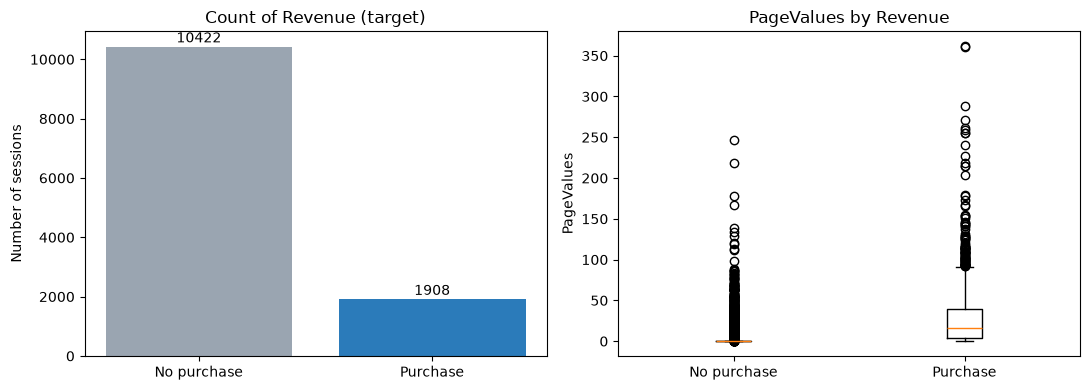

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = df["Revenue"].value_counts()
ax[0].bar(["No purchase", "Purchase"], counts.values, color=["#9aa5b1", "#2b7bba"])
ax[0].set_title("Count of Revenue (target)")
ax[0].set_ylabel("Number of sessions")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 150, str(v), ha="center")

ax[1].boxplot([df[df["Revenue"] == False]["PageValues"].values,
               df[df["Revenue"] == True]["PageValues"].values],
              tick_labels=["No purchase", "Purchase"])
ax[1].set_title("PageValues by Revenue")
ax[1].set_ylabel("PageValues")

plt.tight_layout()
plt.show()

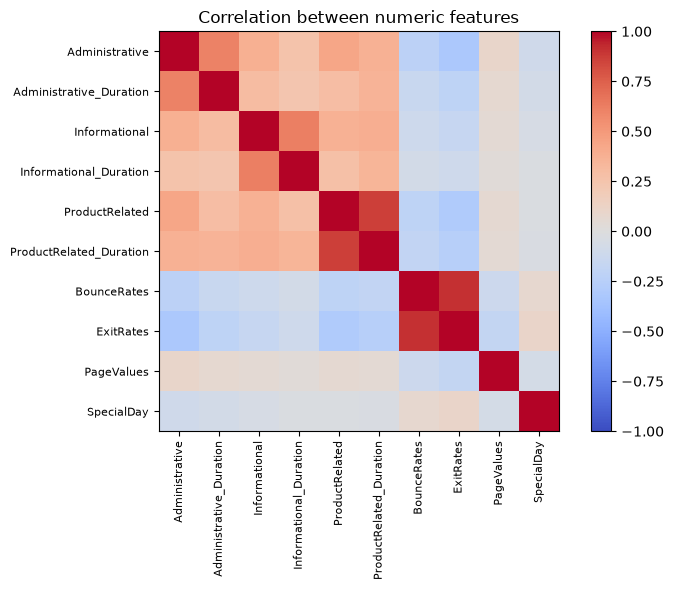

In [19]:
# correlation of the numeric columns with each other
num_check = ["Administrative", "Administrative_Duration", "Informational",
             "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
             "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

corr = df[num_check].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_check)), num_check, rotation=90, fontsize=8)
plt.yticks(range(len(num_check)), num_check, fontsize=8)
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

## 4. Train / test split

`Weekend` and `Revenue` are True/False in the csv, so first I convert them to 0/1.
20% of the data is kept as test data and saved as `test_data.csv`.
The same file is uploaded in the Streamlit app.

In [20]:
df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)

X = df.drop(columns=["Revenue"])
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

test_data = X_test.copy()
test_data["Revenue"] = y_test
test_data.to_csv("test_data.csv", index=False)
print("test_data.csv saved with", test_data.shape[0], "rows")

Train: (9864, 17)  Test: (2466, 17)
test_data.csv saved with 2466 rows


## 5. Preprocessing

The categorical columns have to be one hot encoded for every model.

For the numeric columns I keep two versions:

- preprocessor_scaled - numbers are standardised. Needed by KNN and SVM because they use distances,
  so a column like ProductRelated_Duration (values in thousands) would otherwise dominate.
- preprocessor_plain - numbers are used as it is. Used for Decision Tree and Naive Bayes.

I first scaled for all models, but Gaussian NB gave only 27% accuracy because PageValues is very skewed
(most values are 0, a few are above 300) and after scaling those few rows dominate the gaussian likelihood.
Without scaling Gaussian NB gives 73% accuracy, so I used the plain version for it.

In [21]:
num_features = ["Administrative", "Administrative_Duration", "Informational",
                "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
                "BounceRates", "ExitRates", "PageValues", "SpecialDay", "Weekend"]

cat_features = ["Month", "OperatingSystems", "Browser", "Region",
                "TrafficType", "VisitorType"]

preprocessor_scaled = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

preprocessor_plain = ColumnTransformer([
    ("num", "passthrough", num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

# the transformer is fit only on training data, the same transformer is used on test data
X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_test_scaled = preprocessor_scaled.transform(X_test)

X_train_plain = preprocessor_plain.fit_transform(X_train)
X_test_plain = preprocessor_plain.transform(X_test)

print("Shape after preprocessing:", X_train_scaled.shape)

Shape after preprocessing: (9864, 74)


## 6. Train the 5 classification models

In [22]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), "scaled"),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), "plain"),
    "KNN": (KNeighborsClassifier(n_neighbors=5), "scaled"),
    "Naive Bayes": (GaussianNB(), "plain"),
    "Support Vector Machine": (SVC(kernel="rbf", C=1.0, random_state=42), "scaled"),
}

In [23]:
rows = []

for name, (model, version) in models.items():
    X_tr = X_train_scaled if version == "scaled" else X_train_plain
    X_te = X_test_scaled if version == "scaled" else X_test_plain

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    # SVM (rbf) has no predict_proba, so decision_function is used for the AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)

    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
    })
    print(name, "trained")

results = pd.DataFrame(rows).round(4)
results

Logistic Regression trained
Decision Tree trained
KNN trained
Naive Bayes trained
Support Vector Machine trained


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8808,0.8830,0.7366,0.3586,0.4824,0.4592
1,Decision Tree,0.8658,0.7378,0.5687,0.5524,0.5604,0.4813
2,KNN,0.8759,0.7659,0.6845,0.3691,0.4796,0.4419
3,Naive Bayes,0.7328,0.7728,0.3249,0.6728,0.4382,0.3229
4,Support Vector Machine,0.8869,0.8827,0.7036,0.4660,0.5606,0.5127


## 7. Save the models and the results

The Streamlit app only loads these files, it never trains again.

In [24]:
os.makedirs("model", exist_ok=True)

joblib.dump(preprocessor_scaled, "model/preprocessor_scaled.joblib")
joblib.dump(preprocessor_plain, "model/preprocessor_plain.joblib")

file_names = {
    "Logistic Regression": "logistic_regression",
    "Decision Tree": "decision_tree",
    "KNN": "knn",
    "Naive Bayes": "naive_bayes",
    "Support Vector Machine": "svm",
}

for name, (model, version) in models.items():
    joblib.dump(model, "model/" + file_names[name] + ".joblib")

results.to_csv("model/results.csv", index=False)
print("2 preprocessors, 5 models and results.csv saved in the model folder")

2 preprocessors, 5 models and results.csv saved in the model folder


## 8. Confusion matrix of all the models

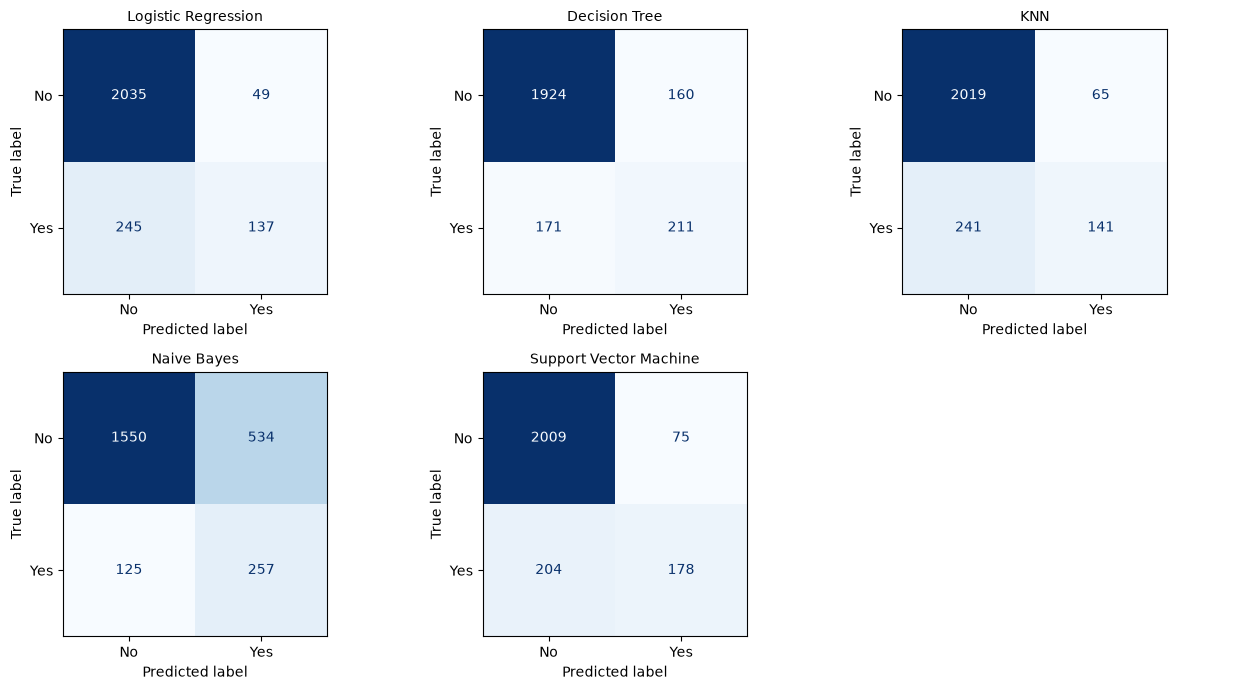

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for ax, (name, (model, version)) in zip(axes.ravel(), models.items()):
    X_te = X_test_scaled if version == "scaled" else X_test_plain
    cm = confusion_matrix(y_test, model.predict(X_te))
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)

axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

## 9. Classification report of the best model

In [26]:
best = models["Support Vector Machine"][0]
print(classification_report(y_test, best.predict(X_test_scaled),
                            target_names=["No purchase", "Purchase"]))

              precision    recall  f1-score   support

 No purchase       0.91      0.96      0.94      2084
    Purchase       0.70      0.47      0.56       382

    accuracy                           0.89      2466
   macro avg       0.81      0.71      0.75      2466
weighted avg       0.88      0.89      0.88      2466



## 10. Short note on the results

- PageValues is the most useful feature. Sessions with PageValues above 20 are almost always purchase sessions.
- SVM and Logistic Regression have the best AUC (0.88) and the best MCC.
- Decision Tree and KNN have less AUC because they do not use a smooth boundary like the other two.
- KNN gives low recall, it marks many real purchase sessions as no purchase.
- Naive Bayes is the weakest model. BounceRates and ExitRates are almost the same column
  (correlation around 0.9) and that breaks the independence assumption of Naive Bayes.

Detailed comparison and observations are written in the README.